# BÁO CÁO GIỮA KỲ MÔN MÁY HỌC
# Đề tài: Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)

### 1. KHAI BÁO THƯ VIỆN VÀ LOAD DATA

### khai báo thư viên

In [1]:
import os
import zipfile
import urllib.request
import datetime as dt
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.model_selection import train_test_split
# Hien thi
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

### Load Data

In [2]:
df= pd.read_csv("data/online_retail_cleaned.csv")
print(df.head())
print("So dong:", df.shape[0])
print("So cot:", df.shape[1])

print("--- 5 DÒNG ĐẦU TIÊN ---")
display(df.head())

print("--- 5 DÒNG CUỐI CÙNG ---")
display(df.tail())

print  (df.info())

   Invoice StockCode                          Description  Quantity  \
0   489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1   489434    79323P                   PINK CHERRY LIGHTS        12   
2   489434    79323W                  WHITE CHERRY LIGHTS        12   
3   489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4   489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

           InvoiceDate  Price  Customer ID         Country  TotalPrice  
0  2009-12-01 07:45:00   6.95        13085  United Kingdom        83.4  
1  2009-12-01 07:45:00   6.75        13085  United Kingdom        81.0  
2  2009-12-01 07:45:00   6.75        13085  United Kingdom        81.0  
3  2009-12-01 07:45:00   2.10        13085  United Kingdom       100.8  
4  2009-12-01 07:45:00   1.25        13085  United Kingdom        30.0  
So dong: 405714
So cot: 9
--- 5 DÒNG ĐẦU TIÊN ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


--- 5 DÒNG CUỐI CÙNG ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
405709,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530,United Kingdom,5.90
405710,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530,United Kingdom,3.75
405711,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530,United Kingdom,3.75
405712,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530,United Kingdom,7.50
405713,538171,21931,JUMBO STORAGE BAG SUKI,2,2010-12-09 20:01:00,1.95,17530,United Kingdom,3.90


<class 'pandas.DataFrame'>
RangeIndex: 405714 entries, 0 to 405713
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      405714 non-null  int64  
 1   StockCode    405714 non-null  str    
 2   Description  405714 non-null  str    
 3   Quantity     405714 non-null  int64  
 4   InvoiceDate  405714 non-null  str    
 5   Price        405714 non-null  float64
 6   Customer ID  405714 non-null  int64  
 7   Country      405714 non-null  str    
 8   TotalPrice   405714 non-null  float64
dtypes: float64(2), int64(3), str(4)
memory usage: 27.9 MB
None


## 2. Tìm hiểu và mô tả dữ liệu 


In [3]:
# Hien thi tat ca cac cot, bao gom ca categorical
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice,405714.0,NaN,NaN,NaN,514762.439603,14102.303514,489434.0,502764.0,515305.0,527105.0,538171.0
StockCode,405714,3997,85123A,3149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,405714,4420,WHITE HANGING HEART T-LIGHT HOLDER,3149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,405714.0,NaN,NaN,NaN,11.788772,29.352644,1.0,2.0,5.0,12.0,600.0
InvoiceDate,405714,17740,2010-03-07 15:34:00,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,405714.0,NaN,NaN,NaN,2.93709,2.946099,0.04,1.25,1.95,3.75,39.95
Customer ID,405714.0,NaN,NaN,NaN,15373.635315,1677.307153,12346.0,14006.0,15326.0,16814.0,18287.0
Country,405714,37,United Kingdom,369984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TotalPrice,405714.0,NaN,NaN,NaN,20.555175,53.94558,0.06,4.95,11.8,19.5,3942.0


### Ý nghĩa và dạng dữ liệu của các thuộc tính 

| STT | Thuộc tính | Dạng dữ liệu | Ý nghĩa và mô tả |
| :---: | :--- | :--- | :--- |
| 1 | **Invoice** | Chuỗi (object/string) | Mã hóa đơn giao dịch. Mỗi hóa đơn có mã định danh riêng. Các mã bắt đầu bằng ký tự C thường biểu thị hóa đơn hủy. |
| 2 | **StockCode** | Chuỗi (object/string) | Mã định danh của sản phẩm. Dùng để phân biệt các sản phẩm trong hệ thống. |
| 3 | **Description** | Chuỗi (object/string) | Mô tả hoặc tên sản phẩm được bán trong giao dịch. |
| 4 | **Quantity** | Số nguyên (int) | Số lượng sản phẩm được mua trong giao dịch. Giá trị âm có thể biểu thị hàng trả lại. |
| 5 | **InvoiceDate** | Ngày giờ (datetime) | Thời điểm hóa đơn được lập, bao gồm ngày và giờ giao dịch. |
| 6 | **Price** | Số thực (float) | Đơn giá của một sản phẩm trong giao dịch, tính theo đơn vị tiền tệ của bộ dữ liệu (GBP). |
| 7 | **Customer ID** | Số nguyên hoặc số thực (int/float) | Mã định danh khách hàng thực hiện giao dịch. Một số giao dịch có thể không có thông tin khách hàng. |
| 8 | **Country** | Chuỗi (object/string) | Quốc gia của khách hàng thực hiện giao dịch. |
| 9 | **TotalPrice** | Số thực (float) | Tổng giá trị của sản phẩm trong dòng giao dịch, được tính bằng số lượng nhân với đơn giá: Quantity × Price. Đây là thuộc tính được tạo thêm trong quá trình xử lý dữ liệu. |

#### Thống kê mô tả
 * Mục đích: Quan sát giá trị trung bình, độ lệch chuẩn, giá trị nhỏ nhất, lớn nhất và các thống kê phù hợp với từng kiểu dữ liệu.

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice,405714.0,NaN,NaN,NaN,514762.439603,14102.303514,489434.0,502764.0,515305.0,527105.0,538171.0
StockCode,405714,3997,85123A,3149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,405714,4420,WHITE HANGING HEART T-LIGHT HOLDER,3149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,405714.0,NaN,NaN,NaN,11.788772,29.352644,1.0,2.0,5.0,12.0,600.0
InvoiceDate,405714,17740,2010-03-07 15:34:00,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,405714.0,NaN,NaN,NaN,2.93709,2.946099,0.04,1.25,1.95,3.75,39.95
Customer ID,405714.0,NaN,NaN,NaN,15373.635315,1677.307153,12346.0,14006.0,15326.0,16814.0,18287.0
Country,405714,37,United Kingdom,369984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TotalPrice,405714.0,NaN,NaN,NaN,20.555175,53.94558,0.06,4.95,11.8,19.5,3942.0


## EDA-Khám phá dữ liệu


#### Kiểm tra dữ liệu thiếu

In [5]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    'So gia tri thieu': missing,
    'Ty le thieu (%)': missing / len(df) * 100
})

missing_df

,So gia tri thieu,Ty le thieu (%)
Invoice,0,0.0
StockCode,0,0.0
Description,0,0.0
Quantity,0,0.0
InvoiceDate,0,0.0
Price,0,0.0
Customer ID,0,0.0
Country,0,0.0
TotalPrice,0,0.0


Nhận xét: không có dữ liệu bị thiếu 

#### Kiểm tra dữ liệu trùng lặp

In [6]:
print("So dong trung lap:", df.duplicated().sum())

So dong trung lap: 6743


#### Kiểm tra có giá trị âm của  thuộc tính số

In [7]:
# Kiểm tra có giá trị âm không
print("Quantity có giá trị âm:", (df["Quantity"] < 0).any())
print("Price có giá trị âm:", (df["Price"] < 0).any())

# Đếm số giá trị âm
print("Số Quantity âm:", (df["Quantity"] < 0).sum())
print("Số Price âm:", (df["Price"] < 0).sum())



Quantity có giá trị âm: False
Price có giá trị âm: False
Số Quantity âm: 0
Số Price âm: 0


#### Kiểm tra phân phối số lượng và đơn giá

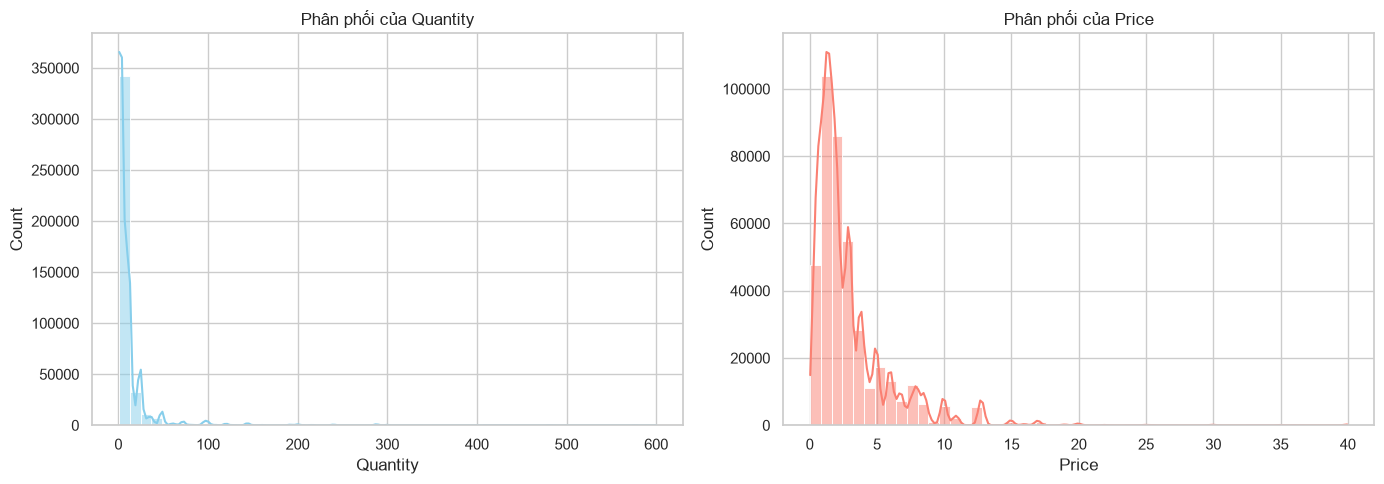

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Quantity'], kde=True, ax=axes[0], color='skyblue', bins=50)
axes[0].set_title('Phân phối của Quantity')

sns.histplot(df['Price'], kde=True, ax=axes[1], color='salmon', bins=50)
axes[1].set_title('Phân phối của Price')

plt.tight_layout()
plt.show()


Nhận xét: Nhận xét: Hai thuộc tính có xu hướng lệch phải, phần lớn giá trị tập trung ở vùng thấp và có một số giá trị lớn xuất hiện với tần suất thấp.

#### Kiểm tra ngoại lệ bằng Boxplot

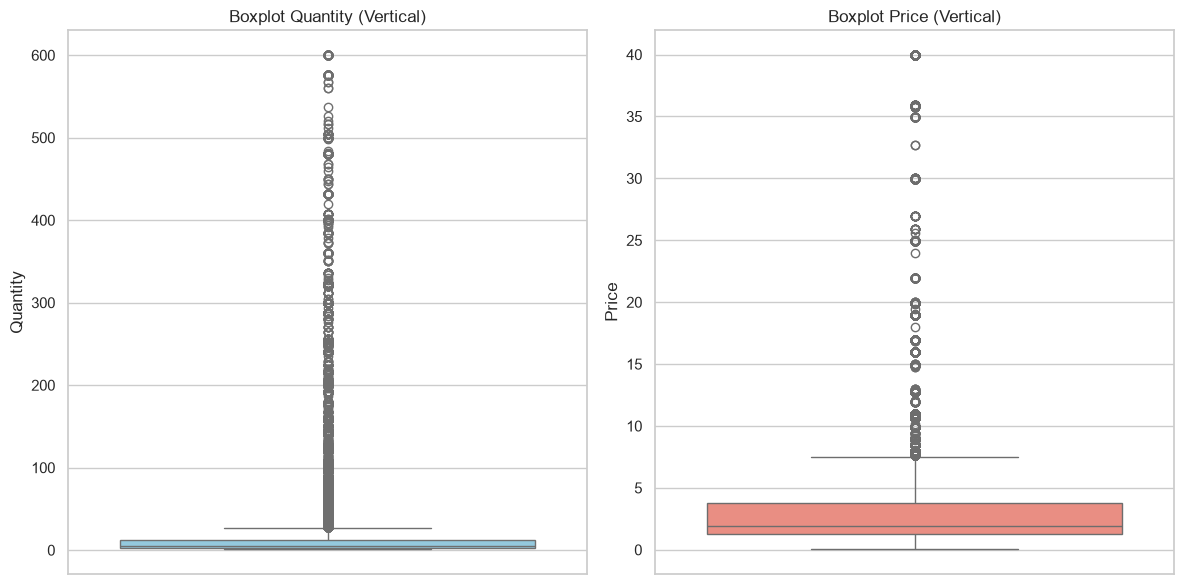

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Khởi tạo khung vẽ gồm 1 hàng và 2 cột
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Boxplot chiều dọc cho Quantity (sử dụng y=)
sns.boxplot(y=df['Quantity'], ax=axes[0], color='skyblue')
axes[0].set_title("Boxplot Quantity (Vertical)")

# Boxplot chiều dọc cho Price (sử dụng y=)
sns.boxplot(y=df['Price'], ax=axes[1], color='salmon')
axes[1].set_title("Boxplot Price (Vertical)")

# Căn chỉnh khoảng cách tự động
plt.tight_layout()
plt.show()

#### Phân tích phân phối TotalPrice

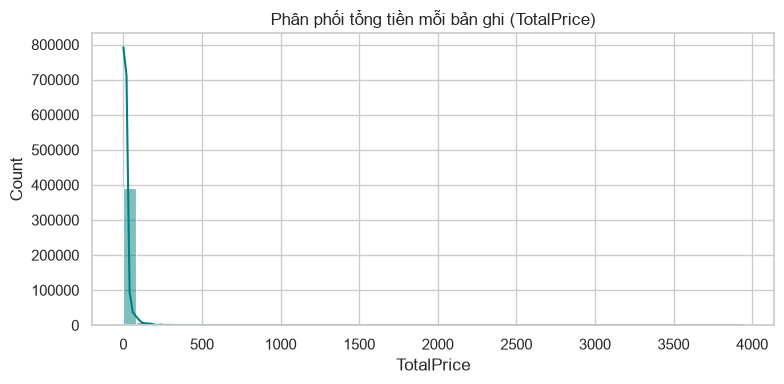

In [10]:
df['TotalPrice'] = df['Quantity'] * df['Price']

total_price = df['TotalPrice'].replace([np.inf, -np.inf], np.nan).dropna()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(x=total_price, kde=True, color='teal', bins=50, ax=ax)
ax.set_title('Phân phối tổng tiền mỗi bản ghi (TotalPrice)')
ax.set_xlabel('TotalPrice')
plt.tight_layout()
plt.show()



#### Phân tích tương quan giữa các thuộc tính số

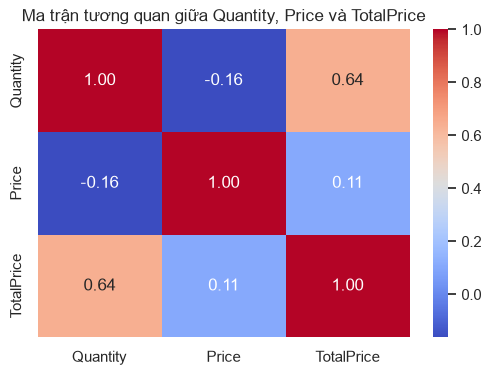

In [11]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Quantity', 'Price', 'TotalPrice']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Ma trận tương quan giữa Quantity, Price và TotalPrice')
plt.show()


#### Phân tích doanh thu theo thời gian

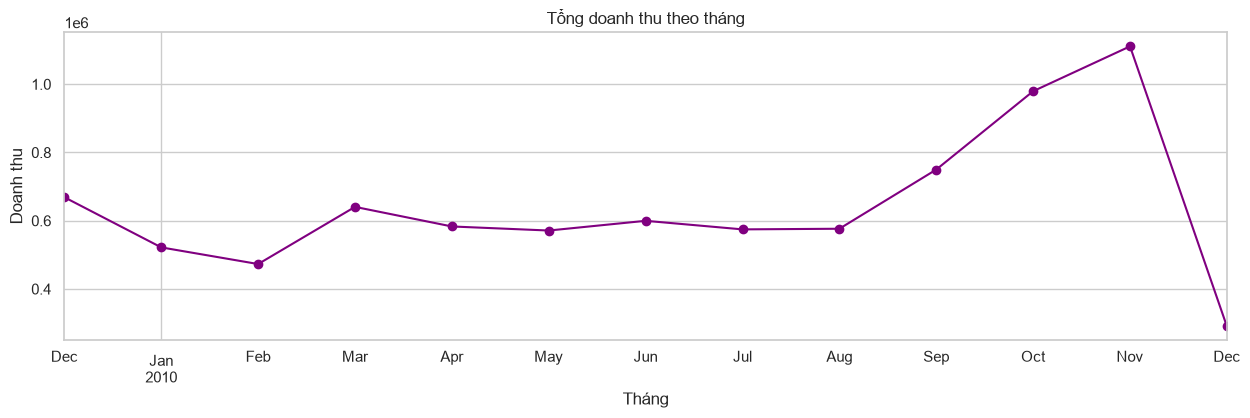

In [12]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df_temp = df.copy()
df_temp['YearMonth'] = df_temp['InvoiceDate'].dt.to_period('M')

monthly_revenue = df_temp.groupby('YearMonth')['TotalPrice'].sum()

plt.figure(figsize=(15, 4))
monthly_revenue.plot(kind='line', marker='o', color='purple')
plt.title('Tổng doanh thu theo tháng')
plt.xlabel('Tháng')
plt.ylabel('Doanh thu')
plt.grid(True)
plt.show()


#### Top sản phẩm bán chạy

C:\Users\Quân\AppData\Local\Temp\ipykernel_13020\3048222612.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette='Blues_r')


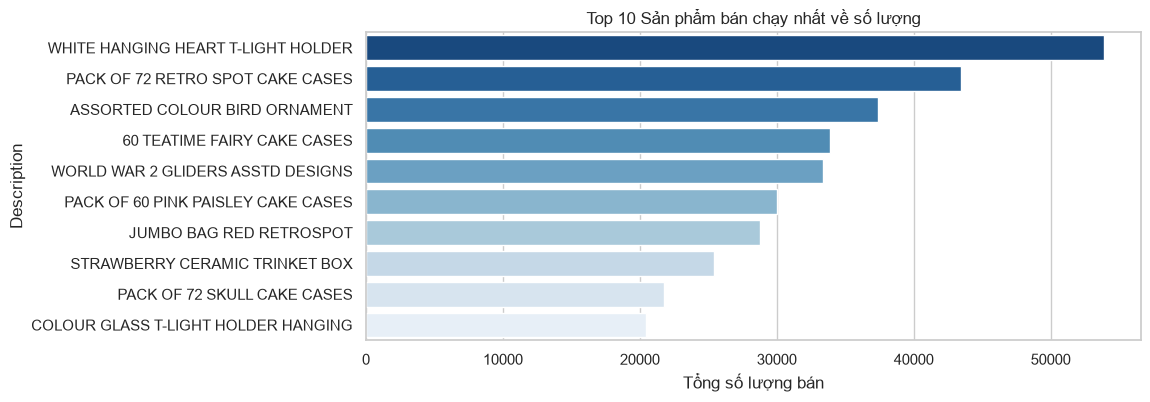

In [13]:
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 4))
sns.barplot(x=top_products.values, y=top_products.index, palette='Blues_r')
plt.title('Top 10 Sản phẩm bán chạy nhất về số lượng')
plt.xlabel('Tổng số lượng bán')
plt.show()


#### Phân tích giao dịch theo quốc gia

C:\Users\Quân\AppData\Local\Temp\ipykernel_13020\3725299563.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis', orient='h')


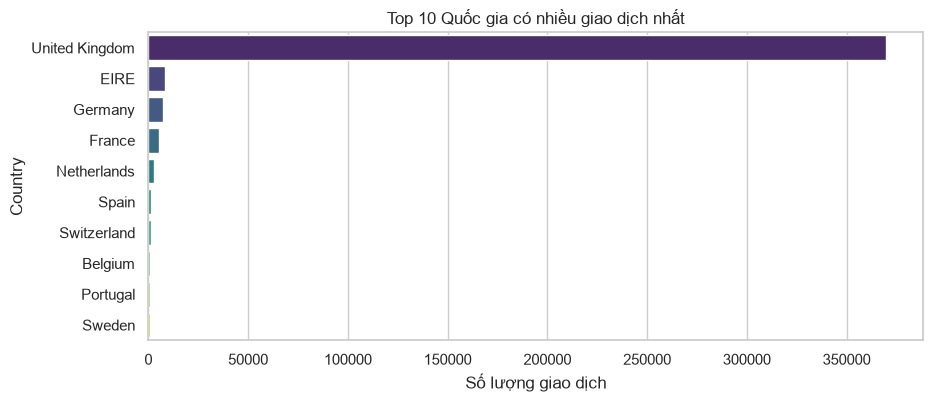

In [14]:
top_countries = df['Country'].value_counts().head(10)

plt.figure(figsize=(10, 4))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis', orient='h')
plt.title('Top 10 Quốc gia có nhiều giao dịch nhất')
plt.xlabel('Số lượng giao dịch')
plt.show()


Tổng kết kết quả EDA:
* Khách hàng tập trung phần lớn ở khu vực United Kingdom.
*  Xuất hiện một số bản ghi trùng lặp cần loại bỏ.
*  Phân phối các biến số bị lệch phải (Right-skewed) rất mạnh.
* Các điểm ngoại lệ cực đoan (Outliers).
* Hệ số tương quan Pearson giữa Quantity (Số lượng) và Price (Đơn giá) là -0.16. Dấu âm chỉ ra mối quan hệ tỷ lệ nghịch: khi giá của một sản phẩm tăng lên thì số lượng mua sản phẩm đó có xu hướng giảm đi (và ngược lại).

 ### Tiền xử lý dữ liệu

In [15]:
df_clean = df.drop_duplicates().copy()
print(f"Kích thước sau khi loại bỏ trùng lặp: {df_clean.shape}")


Kích thước sau khi loại bỏ trùng lặp: (398971, 9)


#### Xử lý dữ liệu thiếu
`CustomerID` là khóa bắt buộc để phân nhóm khách hàng. Do đó, các dòng thiếu `CustomerID` sẽ bị loại bỏ.

In [16]:
df_clean = df_clean.dropna(subset=['Customer ID'])
print(f"Kích thước sau khi loại bỏ CustomerID thiếu: {df_clean.shape}")


Kích thước sau khi loại bỏ CustomerID thiếu: (398971, 9)


Nhận xét:
* CustomerID không có dữ liệu thiếu 

#### Chuyển đổi kiểu dữ liệu

In [17]:
# Đặt lại tên cho các cột theo chuẩn
df_clean.rename(columns={
    'Invoice': 'InvoiceNo', 
    'Price': 'UnitPrice', 
    'Customer ID': 'CustomerID'
}, inplace=True)

df_clean['CustomerID'] = df_clean['CustomerID'].astype(int).astype(str)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)


1. Chuyển cột CustomerID qua 2 bước liên tiếp:
    * Chuyển từ kiểu số thực (float, ví dụ: 12345.0) thành số nguyên (12345).
    * Chuyển tiếp từ số nguyên thành chuỗi ký tự (string, ví dụ: '12345').

Giải thích lý do:
Xóa phần thập phân thừa .0: Ban đầu, do cột CustomerID có chứa giá trị khuyết (NaN), Pandas tự động hiểu cột này là kiểu float64 và ép các mã ID thành dạng 12345.0. Việc ép về int giúp loại bỏ đuôi .0 không cần thiết. 

Bản chất của mã định danh: CustomerID là mã định danh đại diện cho từng khách hàng, không dùng để cộng, trừ, nhân, chia. Việc ép kiểu về chuỗi (str) giúp tránh việc các hàm thống kê ví dụ như (.describe()) tính toán nhầm các chỉ số vô nghĩa (như trung bình cộng mean hay tổng sum của mã khách hàng).

2.  Sử dụng hàm pd.to_datetime() để ép kiểu cột InvoiceDate từ dạng chuỗi văn bản (String/Object, ví dụ: '2021-12-01 08:26:00') sang kiểu thời gian chuẩn của Pandas (datetime64).

Giải thích lý do:

Trích xuất thông tin thời gian: Khi ở dạng datetime64, bạn mới có thể dễ dàng truy xuất các thành phần thời gian như năm, tháng, ngày, giờ, thứ trong tuần (ví dụ: df['InvoiceDate'].dt.month hoặc df['InvoiceDate'].dt.day_name()).

Tính toán khoảng cách thời gian (Bắt buộc cho RFM): Để tính chỉ số Recency (Số ngày tính từ lần mua gần nhất đến ngày tham chiếu), bạn bắt buộc phải thực hiện phép trừ giữa 2 mốc thời gian (ví dụ: reference_date - max(InvoiceDate)).

3. Chuyển tất cả giá trị trong cột mã hóa đơn InvoiceNo về dạng chuỗi văn bản (str).

Giải thích lý do:

Đồng bộ dữ liệu hỗn hợp: Trong các bộ dữ liệu bán hàng (như Online Retail), mã hóa đơn thường chứa cả số (ví dụ: 536365) lẫn chữ cái biểu thị hóa đơn hủy (ví dụ: C536379). Việc chuyển về str giúp đảm bảo toàn bộ dữ liệu trong cột có cùng một kiểu dữ liệu đồng nhất.

Hỗ trợ xử lý chuỗi (String operations): Giúp bạn sử dụng các hàm xử lý chuỗi để lọc dữ liệu ở các bước sau, chẳng hạn như kiểm tra và loại bỏ hóa đơn hủy bắt đầu bằng chữ 'C' (df['InvoiceNo'].str.startswith('C')).

#### kiểm tra có xuất hiện hóa đơn hủy hay không


In [18]:
# Hóa đơn hủy thường bắt đầu bằng ký tự 'C'
cancelled_mask = df_clean['InvoiceNo'].str.startswith('C', na=False)
print(f"Số lượng hóa đơn hủy: {cancelled_mask.sum()}")


Số lượng hóa đơn hủy: 0


Nhận xét: Dữ liệu trên không có đơn nào bị hủy

#### Kiểm tra và xử lý hàng trả lại


In [19]:
# Loại bỏ các giao dịch có Quantity <= 0 hoặc UnitPrice <= 0
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
print(f"Kích thước sau khi lọc Quantity & UnitPrice > 0: {df_clean.shape}")


Kích thước sau khi lọc Quantity & UnitPrice > 0: (398971, 9)


#### Kiểm tra Quantity và UnitPrice bất thường

In [20]:
# Kiểm tra các giá trị cực đại bất thường
print("Q99 của Quantity:", df_clean['Quantity'].quantile(0.99))
print("Q99 của UnitPrice:", df_clean['UnitPrice'].quantile(0.99))


Q99 của Quantity: 120.0
Q99 của UnitPrice: 12.75


* Quantity = 120: Có 99% giá trị trong cột Quantity nhỏ hơn hoặc bằng 120. Khoảng 1% dữ liệu còn lại có số lượng lớn hơn 120, cần được kiểm tra để xác định các giao dịch có số lượng bất thường.

* UnitPrice = 12.75: Có 99% giá trị trong cột UnitPrice nhỏ hơn hoặc bằng 12.75. Khoảng 1% dữ liệu còn lại có đơn giá cao hơn 12.75, cần được xem xét để phát hiện các giá trị cực đại.

In [21]:
# Hàm kiểm tra ngoại lệ bằng IQR
def check_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower) | (df[column] > upper)]

    print(f"\n--- {column} ---")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Ngưỡng dưới:", lower)
    print("Ngưỡng trên:", upper)
    print("Số lượng ngoại lệ:", len(outliers))

    return outliers

# Kiểm tra Quantity và UnitPrice
outliers_quantity = check_outliers(df_clean, 'Quantity')
outliers_price = check_outliers(df_clean, 'UnitPrice')


--- Quantity ---
Q1: 2.0
Q3: 12.0
IQR: 10.0
Ngưỡng dưới: -13.0
Ngưỡng trên: 27.0
Số lượng ngoại lệ: 25902

--- UnitPrice ---
Q1: 1.25
Q3: 3.75
IQR: 2.5
Ngưỡng dưới: -2.5
Ngưỡng trên: 7.5
Số lượng ngoại lệ: 31356


nhận xét chung về hai thuộc tính dựa trên kết quả và boxplot:
- Quantity có nhiều giá trị lớn hơn ngưỡng IQR, có thể là những giao dịch mua số lượng lớn.
- UnitPrice có nhiều giá trị lớn hơn ngưỡng IQR, có thể phản ánh sự khác biệt về giá bán sản phẩm.
- Các giá trị ngoại lệ chưa đủ cơ sở để kết luận là dữ liệu sai lệch nên chưa tiến hành loại bỏ.

#### Kiểm tra và tính lại TotalPrice

In [22]:
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']


#### Xuất file dữ liệu đã được làm sạch 

In [23]:
df_clean.to_csv("data/data_clean.csv", index=False, encoding="utf-8-sig")
print("Đã xuất dữ liệu ra file data_clean.csv")

Đã xuất dữ liệu ra file data_clean.csv


### Feature Engineering (Tính chỉ số RFM) & Chia tập dữ liệu Train/Validation 

 #### Recency (R - Độ gần đây): Số ngày tính từ lần mua hàng gần nhất của khách hàng đến mốc thời gian chốt phân tích.
 $$\text{Recency} = \text{Snapshot Date} - \max(\text{InvoiceDate})$$
 Khách hàng có $R$ càng nhỏ chứng tỏ họ vừa mới quay lại mua hàng


#### Frequency (F - Tần suất): số lượng hóa đơn mà khách hàng đã thực hiện.
$$\text{Frequency} = \text{CountUnique}(\text{InvoiceNo})$$
Khách hàng có $F$ càng cao chứng tỏ họ là khách hàng thân thiết.

#### Monetary (M - Giá trị tiền tệ): Tổng số tiền khách hàng đã chi tiêu tích lũy.
$$\text{Monetary} = \sum (\text{Quantity} \times \text{UnitPrice})$$
(Khách hàng có $M$ càng cao đóng góp doanh thu càng lớn).

#### TÍNH TOÁN BỘ CHỈ SỐ RFM VÀ CHIA TẬP TRAIN / VALIDATION

In [24]:
# Mốc thời gian chốt phân tích = Ngày giao dịch muộn nhất + 1 ngày
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"Mốc thời gian chốt Recency (Snapshot Date): {snapshot_date.strftime('%Y-%m-%d')}")

# Gom nhóm tính các chỉ số RFM
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                                 # Frequency
    'TotalPrice': 'sum'                                      # Monetary
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print("\n--- 5 Dòng dữ liệu RFM mẫu ---")
display(rfm.head())

# --- LƯU FILE CSV 2: Bảng chỉ số RFM ---
rfm.to_csv("data/rfm_data.csv", index=False)
print("💾 Đã xuất file thành công: 'rfm_data.csv'")

# --- Chia tập Train (80%) và Validation (20%) ---
train_rfm, val_rfm = train_test_split(rfm, test_size=0.2, random_state=42)

print(f"\n✅ Tập Train: {train_rfm.shape[0]} khách hàng")
print(f"✅ Tập Validation: {val_rfm.shape[0]} khách hàng")

# Log-transform giảm độ lệch Skewness
X_train_log = np.log1p(train_rfm[['Recency', 'Frequency', 'Monetary']])
X_val_log = np.log1p(val_rfm[['Recency', 'Frequency', 'Monetary']])

# StandardScaler (Fit duy nhất trên Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)
X_val_scaled = scaler.transform(X_val_log)
# --- XUẤT VÀ LƯU HAI FILE DỮ LIỆU CỐ ĐỊNH ---
train_rfm.to_csv("data/rfm_train.csv", index=False)
val_rfm.to_csv("data/rfm_val.csv", index=False)

print("💾 Đã lưu thành công:")
print(f"   - rfm_train.csv ({train_rfm.shape[0]:,} khách hàng)")
print(f"   - rfm_val.csv   ({val_rfm.shape[0]:,} khách hàng)")

Mốc thời gian chốt Recency (Snapshot Date): 2010-12-10

--- 5 Dòng dữ liệu RFM mẫu ---


,CustomerID,Recency,Frequency,Monetary
0,12346,165,11,372.86
1,12347,3,2,1323.32
2,12348,74,1,221.16
3,12349,43,2,2221.14
4,12351,11,1,300.93


💾 Đã xuất file thành công: 'rfm_data.csv'

✅ Tập Train: 3420 khách hàng
✅ Tập Validation: 855 khách hàng
💾 Đã lưu thành công:
   - rfm_train.csv (3,420 khách hàng)
   - rfm_val.csv   (855 khách hàng)


* Ở đây để tránh tình trạng data leak nên ta sẽ chia train và validation trước rồi mới chuẩn hóa dữ liệu tranh việc dữ liệu train bị fit với dữ liệu validation

## Xây dựng mô hình phân cụm

### Giới thiệu các thuật toán và các chỉ số đánh giá
Thuật toán sử dụng:
1. **K-Means Clustering:** Phân cụm dựa trên tâm (Centroid-based). Nhanh, hiệu quả với cụm dạng hình cầu.
2. **Hierarchical Clustering (Agglomerative):** Phân cụm phân cấp từ dưới lên dựa trên ma trận khoảng cách.
3. **DBSCAN:** Phân cụm dựa trên mật độ (Density-based). Có khả năng phát hiện cụm có hình dạng bất kỳ và nhận diện nhiễu (Noise).

Chỉ số đánh giá:
 1. Silhouette ScoreQuy tắc: Càng gần $+1$ càng tốt (Dương là tốt, Am là sai).
 2. Davies-Bouldin IndexQuy tắc: Càng nhỏ (càng gần $0$) càng tốt.
 3. Calinski-Harabasz IndexQuy tắc: Càng lớn (càng cao) càng tốt.

### Import các Module Mô hình từ Source/models/

In [25]:
# Import các lớp mô hình từ cấu trúc thư mục Source/models/
from Source.models.base_model import BaselineKMeans
from Source.models.kmeans_model import TunedKMeans
from Source.models.hierarchical_model import HierarchicalModel
from Source.models.dbscan_model import DBSCANModel
from Source.logger import evaluate_and_log
from Source.init import PATH_EXPERIMENT_LOG, PATH_RFM_TRAIN, PATH_RFM_VAL

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

print("✅ Đã nạp thành công các module mô hình từ Source/models!")

✅ Đã nạp thành công các module mô hình từ Source/models!


### Huấn luyện Baseline (K-Means)

In [26]:

# Huấn luyện mô hình Baseline K-Means (K=3, chưa tinh chỉnh)
baseline = BaselineKMeans(n_clusters=3, random_state=42)
base_metrics, base_labels, base_model = baseline.run(X_train_scaled, log_file=PATH_EXPERIMENT_LOG)

print("✅ Đã hoàn thành Baseline K-Means:")
display(pd.DataFrame([base_metrics]))

✅ Đã hoàn thành Baseline K-Means:


,Timestamp,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2026-11-07 17:56:59,"Baseline: K-Means (K=3, Untuned)",0.3286,1.0713,2751.479


### Huấn luyện Hierarchical Clustering (Chưa tinh chỉnh K=4)

In [27]:
# Huấn luyện mô hình Hierarchical Clustering với K=4 (Ward linkage)
hierarchical_init = HierarchicalModel(n_clusters=4, linkage='ward')
h_metrics_init, h_labels_init, h_model_init = hierarchical_init.run(X_train_scaled, log_file=PATH_EXPERIMENT_LOG)

print("✅ Đã hoàn thành Hierarchical Clustering ban đầu:")
display(pd.DataFrame([h_metrics_init]))

✅ Đã hoàn thành Hierarchical Clustering ban đầu:


,Timestamp,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2026-11-07 17:57:00,"Mô hình 2: Hierarchical (K=4, linkage='ward')",0.2611,1.0428,2065.597


### Huấn luyện mô hình DBSCAN ban đầu

In [28]:
# Huấn luyện mô hình DBSCAN ban đầu (eps=0.6, min_samples=10)
dbscan_init = DBSCANModel(eps=0.6, min_samples=10)
db_metrics_init, db_labels_init, db_model_init = dbscan_init.run(X_train_scaled, log_file=PATH_EXPERIMENT_LOG)

print("✅ Đã hoàn thành DBSCAN ban đầu:")
display(pd.DataFrame([db_metrics_init]))

✅ Đã hoàn thành DBSCAN ban đầu:


,Timestamp,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2026-11-07 17:57:00,"Mô hình 3: DBSCAN (eps=0.6, min_samples=10)",N/A,N/A,N/A


#### Lưu kết quả phân cụm ban đầu

In [31]:
import os
from Source.init import DATA_DIR

# 1. Tạo DataFrame tổng hợp nhãn phân cụm ban đầu (kèm CustomerID)
df_initial_clusters = pd.DataFrame({
    'CustomerID': train_rfm['CustomerID'].values,
    'Baseline_KMeans': base_labels,
    'Hierarchical_Init': h_labels_init,
    'DBSCAN_Init': db_labels_init
})

print("--- 5 dòng kết quả phân cụm ban đầu ---")
display(df_initial_clusters.head())

# 2. Định nghĩa đường dẫn lưu file trong thư mục data/
path_excel_init = os.path.join(DATA_DIR, "initial_clusters_train.xlsx")
path_csv_init = os.path.join(DATA_DIR, "initial_clusters_train.csv")

# 3. Xuất ra file Excel và CSV trong thư mục data/
df_initial_clusters.to_excel(path_excel_init, index=False, engine='openpyxl')
df_initial_clusters.to_csv(path_csv_init, index=False)

print("\n💾 Đã lưu thành công các file phân cụm ban đầu vào thư mục 'data/':")
print(f"   - '{path_excel_init}'")
print(f"   - '{path_csv_init}'")

--- 5 dòng kết quả phân cụm ban đầu ---


,CustomerID,Baseline_KMeans,Hierarchical_Init,DBSCAN_Init
0,16088,0,2,0
1,13327,2,0,0
2,13966,1,2,0
3,18144,2,0,0
4,17915,1,2,0



💾 Đã lưu thành công các file phân cụm ban đầu vào thư mục 'data/':
   - 'c:\Users\Quân\Desktop\ml_group\data\initial_clusters_train.xlsx'
   - 'c:\Users\Quân\Desktop\ml_group\data\initial_clusters_train.csv'


### TỐI ƯU THAM SỐ MÔ HÌNH

#### Tìm số cụm K bằng Elbow Method

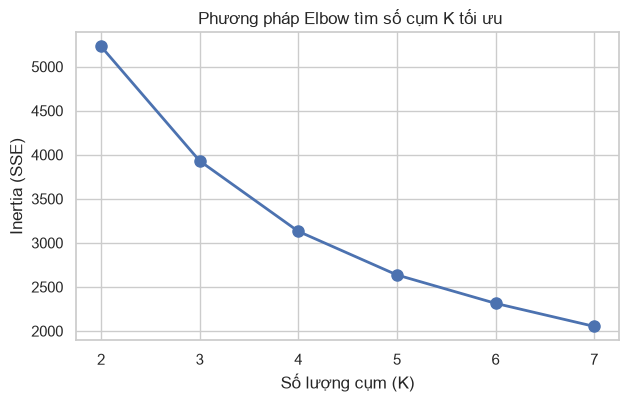

In [33]:
# Tinh chỉnh tìm K tối ưu cho K-Means
kmeans_tuner = TunedKMeans(random_state=42)
best_k, sse, sil_scores = kmeans_tuner.tune(X_train_scaled, k_range=range(2, 8))

# Biểu đồ Phương pháp Elbow
plt.figure(figsize=(7, 4))
plt.plot(list(sse.keys()), list(sse.values()), 'bo-', linewidth=2, markersize=8)
plt.title(' Phương pháp Elbow tìm số cụm K tối ưu')
plt.xlabel('Số lượng cụm (K)')
plt.ylabel('Inertia (SSE)')
plt.grid(True)
plt.show()

#### Tìm số cụm K bằng Silhouette Score

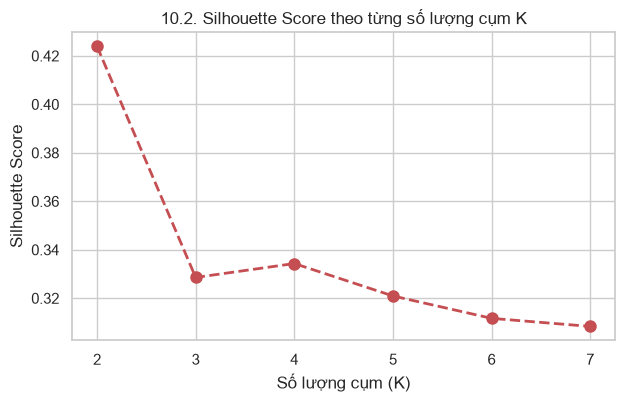

✅ Số cụm K tối ưu tìm được từ Silhouette Score: K = 2


In [34]:
# Biểu đồ Silhouette Score theo từng K
plt.figure(figsize=(7, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), 'ro--', linewidth=2, markersize=8)
plt.title('10.2. Silhouette Score theo từng số lượng cụm K')
plt.xlabel('Số lượng cụm (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

print(f"✅ Số cụm K tối ưu tìm được từ Silhouette Score: K = {best_k}")

Điều chỉnh tham số K-Means

In [35]:
# Huấn luyện mô hình K-Means Tuned với K tối ưu (K=best_k)
kmeans_tuned = TunedKMeans(random_state=42)
m1_metrics, m1_train_labels, trained_kmeans_model = kmeans_tuned.run(
    X_train_scaled, 
    k=best_k, 
    log_file=PATH_EXPERIMENT_LOG
)

print(f"✅ Đã huấn luyện Tuned K-Means với K={best_k}:")
display(pd.DataFrame([m1_metrics]))

✅ Đã huấn luyện Tuned K-Means với K=2:


,Timestamp,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2026-11-07 18:48:47,Mô hình 1: K-Means (Tuned K=2),0.4239,0.9078,3287.3052


Tinh chỉnh Hierarchical với K=best_k

In [36]:
hierarchical_tuned = HierarchicalModel(n_clusters=best_k, linkage='ward')
m2_metrics, m2_train_labels, trained_hierarchical_model = hierarchical_tuned.run(
    X_train_scaled, 
    log_file=PATH_EXPERIMENT_LOG
)

print(f"✅ Đã huấn luyện Tuned Hierarchical với K={best_k}:")
display(pd.DataFrame([m2_metrics]))

✅ Đã huấn luyện Tuned Hierarchical với K=2:


,Timestamp,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2026-11-07 18:53:23,"Mô hình 2: Hierarchical (K=2, linkage='ward')",0.4144,0.8818,2681.1695


Nhận xét:
* Giá trị Inertia (SSE) giảm mạnh nhất trong khoảng $K \in [2, 4]$.   
* Tại vị trí $K = 4$, đồ thị xuất hiện điểm "gập khuỷu tay" (Elbow Point), sau đó tốc độ giảm của SSE trở nên chậm và phẳng hơn hẳn.   
* Do đó, kết hợp giữa phương pháp Elbow và Silhouette Score, lựa chọn $K = 4$ làm số lượng cụm tối ưu vừa đảm bảo tính giảm thiểu sai số nội cụm, vừa cho ra số nhóm khách hàng hợp lý và dễ giải thích trong bài toán phân khúc kinh doanh RFM.

In [30]:
!jupyter nbconvert --to html Notebook.ipynb

[NbConvertApp] Converting notebook Notebook.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 711480 bytes to Notebook.html
